# Chapitre 13 - Cours 2 : dégrouper la base de données

Le cours 1 a montré qu'une organisation qui dérive ses données d'un journal fait, à
grande échelle, ce qu'une base de données fait en interne quand elle tient ses index à
jour. Ce notebook prend l'analogie au sérieux : que se passe-t-il si l'on **sépare les
composants** d'une base (journal, index, vues matérialisées, code applicatif) et qu'on
les recompose avec des flux ? Il couvre les sections *Unbundling Databases* (*Composing
Data Storage Technologies*) et *Designing Applications
Around Dataflow*.

**Plan.**

1. Bases de données, Unix et dégroupage.
2. Créer un index, c'est dériver une vue.
3. La méta-base de données de toute l'organisation.
4. Faire fonctionner le dégroupage : le couplage lâche.
5. Dégroupé ou intégré ?
6. Le code applicatif comme fonction de dérivation : le modèle du tableur.
7. Séparer le code et l'état, et s'abonner aux changements.
8. Processeurs de flux et services.

In [1]:
import math
import random
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Bases de données, Unix et dégroupage (section *Unbundling Databases*)

Vu de haut, une base de données, un moteur de traitement par lots ou de flux et un
système d'exploitation font la même chose : ils **stockent** des données et permettent
de les **traiter et interroger**. La base range des enregistrements d'un modèle de
données (lignes, documents, sommets), le système de fichiers range des fichiers ; ce
sont deux systèmes de gestion de l'information (avec de grosses différences pratiques :
dix millions de petits fichiers dans un répertoire gênent la plupart des systèmes de
fichiers, dix millions de petites lignes dans une table sont banals).

Les deux traditions ont pourtant des philosophies opposées, nées au même moment (Unix
et le modèle relationnel datent tous deux du début des années 1970) :

| | Unix | bases relationnelles |
|---|---|---|
| abstraction | mince couche logique au-dessus du matériel | haut niveau : cache structures disque, concurrence, reprise |
| briques | fichiers = suites d'octets, tubes (pipes) | SQL, transactions |
| « simple » parce que... | peu de choses entre vous et le matériel | une requête déclarative courte mobilise optimiseur, index, jointures, réplication |
| composition | petits outils assemblés par le shell | un seul système intégré |

Le mouvement NoSQL peut se lire comme l'application de l'esprit Unix (abstractions de
bas niveau) au stockage transactionnel distribué. Le livre tente de **réconcilier** les
deux : garder les abstractions de haut niveau des bases, mais les construire en
composant des briques spécialisées, comme le shell compose des outils.

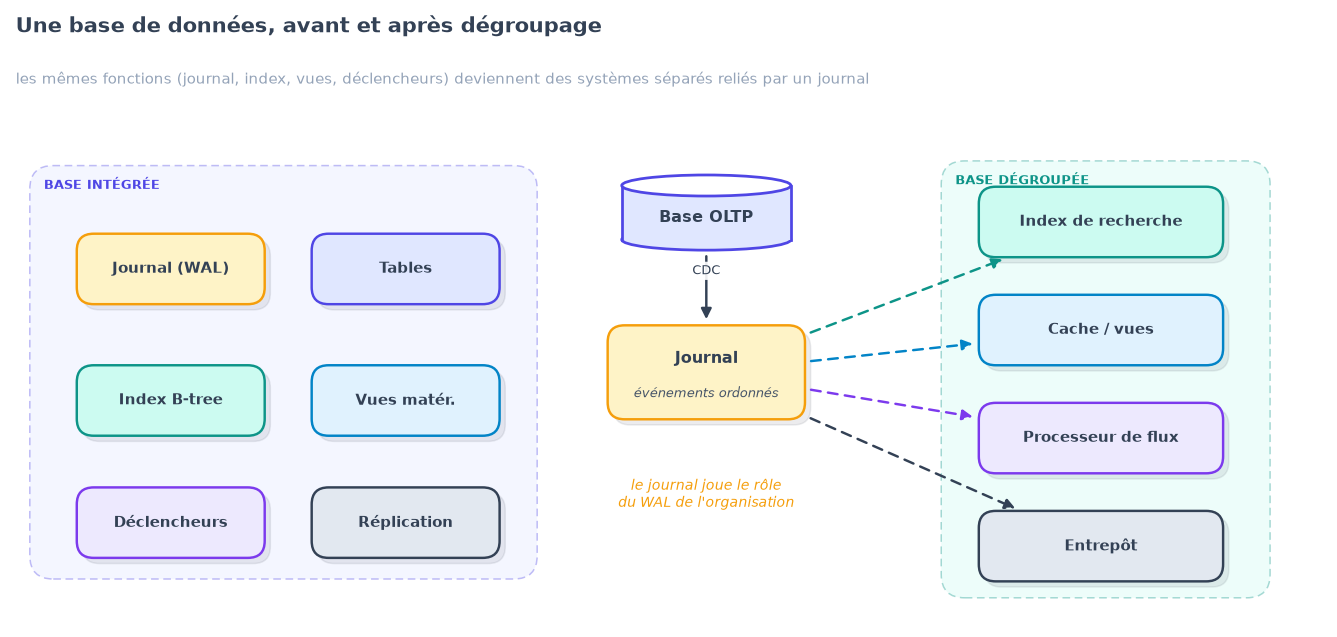

In [2]:
d = Diagram(14, 5.6, title="Une base de données, avant et après dégroupage",
            subtitle="les mêmes fonctions (journal, index, vues, déclencheurs) deviennent des systèmes séparés reliés par un journal")
d.group(0.2, 0.5, 5.6, 4.9, "base intégrée", color=INDIGO)
inner = [("wal", "Journal (WAL)", 1.7, 3.8, AMBER), ("tbl", "Tables", 4.2, 3.8, INDIGO),
         ("ix", "Index B-tree", 1.7, 2.4, TEAL), ("mv", "Vues matér.", 4.2, 2.4, SKY),
         ("trg", "Déclencheurs", 1.7, 1.1, VIOLET), ("rep", "Réplication", 4.2, 1.1, SLATE)]
for name, txt, x, y, c in inner:
    d.box(name, x, y, txt, color=c, w=2.0, h=0.75, fontsize=9.5)
d.box("log", 7.4, 2.7, "Journal", sub="événements ordonnés", color=AMBER, w=2.1, h=1.0)
outer = [("es", "Index de recherche", 11.6, 4.3, TEAL), ("cache", "Cache / vues", 11.6, 3.15, SKY),
         ("sp", "Processeur de flux", 11.6, 2.0, VIOLET), ("dwh", "Entrepôt", 11.6, 0.85, SLATE)]
d.group(9.9, 0.3, 13.4, 4.95, "base dégroupée", color=TEAL)
for name, txt, x, y, c in outer:
    d.box(name, x, y, txt, color=c, w=2.6, h=0.75, fontsize=9.5)
    d.arrow("log", name, style="dashed", color=c)
d.box("db", 7.4, 4.4, "Base OLTP", color=INDIGO, kind="db", w=1.8, h=0.8)
d.arrow("db", "log", "CDC")
d.note(7.4, 1.4, "le journal joue le rôle\ndu WAL de l'organisation", color=AMBER)
d.show()

> **À retenir.** Unix compose de petits outils de bas niveau ; les bases offrent une
> abstraction de haut niveau intégrée. Dégrouper la base, c'est chercher le meilleur des
> deux : des fonctions de base de données (index, vues, déclencheurs) fournies par des
> systèmes séparés, assemblés par un journal.

## 2. Créer un index, c'est dériver une vue (sections *Composing Data Storage Technologies* et *Creating an index*)

Une base offre index secondaires, vues matérialisées (des caches de résultats de
requêtes), journaux de réplication, parfois des index plein texte. Les chapitres
11 et 12 ont construit les mêmes choses **à l'extérieur** de la base :
index de recherche, maintenance de vues matérialisées, réplication vers des systèmes
dérivés par CDC. Le parallèle est frappant quand on regarde ce que fait `CREATE INDEX`
sans verrouiller la table :

1. parcourir un **instantané cohérent** de la table, extraire et trier les valeurs indexées,
   écrire l'index ;
2. appliquer le **retard** : toutes les écritures faites depuis l'instantané ;
3. ensuite, tenir l'index à jour à chaque écriture.

C'est exactement la mise en place d'un nouveau suiveur (chapitre 6) ou
l'amorçage d'un CDC par un instantané initial (chapitre 12). Implémentons-le
(`dfl.IndexBuilder`) sur une table de commandes indexée par statut, pendant que les
écritures continuent.

In [3]:
rng = random.Random(3)
statuts = ["créée", "payée", "expédiée", "livrée", "annulée"]
changes = []
for i in range(6000):
    k = rng.randrange(800)
    changes.append(("del", k, None) if rng.random() < 0.05 else ("put", k, rng.choice(statuts)))
snap_at = 3000                                           # l'instantané est pris après 3 000 changements

builder = dfl.IndexBuilder()
builder.load_snapshot(dfl.replay_table(changes, snap_at), snap_at)
after_snapshot = builder.as_dict()
builder.catch_up(changes)                                 # rattrapage du retard, puis suivi
truth = dfl.index_from_table(dfl.replay_table(changes))
def n_wrong(idx):
    keys = set(idx) | set(truth)
    return sum(len(set(idx.get(v, [])) ^ set(truth.get(v, []))) for v in keys)
pd.DataFrame({"étape": ["instantané seul", "instantané + rattrapage"],
              "entrées d'index fausses": [n_wrong(after_snapshot), n_wrong(builder.as_dict())],
              "changements appliqués après l'instantané": [0, builder.applied]})

,étape,entrées d'index fausses,changements appliqués après l'instantané
0,instantané seul,1191,0
1,instantané + rattrapage,0,3000


Sans l'étape 2, l'index construit sur l'instantané est faux pour plusieurs centaines
d'entrées : toutes les commandes modifiées depuis. Avec le rattrapage, il coïncide
exactement avec un index construit d'un coup sur l'état final. **Créer un index, c'est
retraiter les données existantes pour en dériver une nouvelle vue.** L'état de départ
est un instantané plutôt qu'un journal complet, mais les deux sont proches (un
instantané est la compaction d'un journal).

**Combien de temps dure la construction ?** Si l'on parcourt l'instantané à $S$ lignes/s
pendant que les écritures arrivent à $r$/s, puis qu'on rattrape à $c$/s ($c > r$), le
retard accumulé pendant le parcours de $N$ lignes vaut $rN/S$ et se résorbe en
$\frac{rN/S}{c - r}$ secondes.

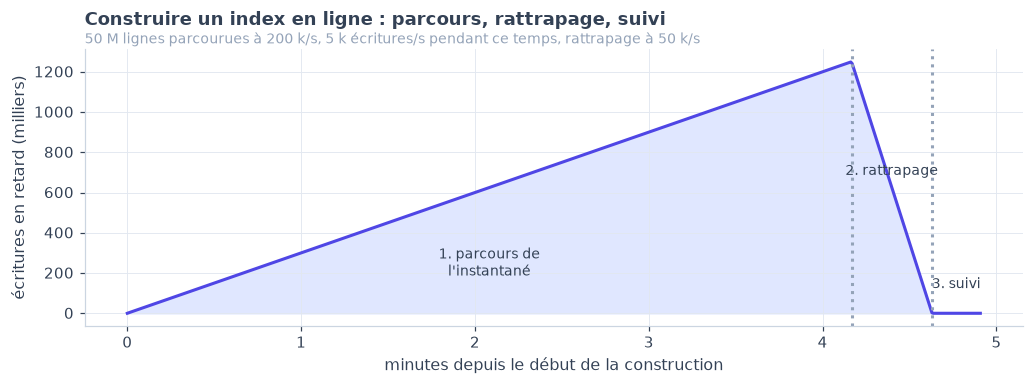

parcours : 4.2 min ; retard accumulé : 1.25 M écritures ; rattrapage : 28 s


In [4]:
N, S, r_, c_ = 50e6, 200e3, 5e3, 50e3
t_scan = N / S
backlog = r_ * t_scan
t_catch = backlog / (c_ - r_)
t = np.linspace(0, t_scan + t_catch * 1.6, 600)
lag = np.where(t <= t_scan, r_ * t, np.maximum(0, backlog - (c_ - r_) * (t - t_scan)))
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.fill_between(t / 60, lag / 1e3, color=LIGHT[INDIGO]); ax.plot(t / 60, lag / 1e3, color=INDIGO)
ax.axvline(t_scan / 60, color=GRAY, ls=":"); ax.axvline((t_scan + t_catch) / 60, color=GRAY, ls=":")
ax.text(t_scan / 120, backlog / 1e3 * 0.15, "1. parcours de\nl'instantané", ha="center", fontsize=9, color=SLATE)
ax.text((t_scan + t_catch / 2) / 60, backlog / 1e3 * 0.55, "2. rattrapage", ha="center", fontsize=9, color=SLATE)
ax.text((t_scan + t_catch * 1.3) / 60, backlog / 1e3 * 0.1, "3. suivi", ha="center", fontsize=9, color=SLATE)
ax.set_xlabel("minutes depuis le début de la construction"); ax.set_ylabel("écritures en retard (milliers)")
ax.set_title("Construire un index en ligne : parcours, rattrapage, suivi")
subtitle(ax, "50 M lignes parcourues à 200 k/s, 5 k écritures/s pendant ce temps, rattrapage à 50 k/s")
plt.tight_layout(); plt.show()
print(f"parcours : {t_scan / 60:.1f} min ; retard accumulé : {backlog / 1e6:.2f} M écritures ; rattrapage : {t_catch:.0f} s")

Le parcours dure un peu plus de quatre minutes et accumule 1,25 million d'écritures en
retard, rattrapées en moins d'une demi-minute. Le même raisonnement dimensionne
l'amorçage d'un nouveau système dérivé par CDC : la marge $c - r$ entre la vitesse de
rattrapage et le débit d'écriture décide de tout (si $c \le r$, on ne rattrape jamais).

> **À retenir.** `CREATE INDEX` = instantané + rattrapage du journal + suivi : c'est la
> même mécanique que l'ajout d'un suiveur ou l'amorçage d'un CDC. Un index est une vue
> dérivée, et la base sait déjà dériver des vues ; le dégroupage applique cette
> mécanique à des systèmes séparés.

## 3. La méta-base de données de toute l'organisation (sections *The meta-database of everything*, *Federated databases* et *Unbundled databases*)

Sous cet angle, le flux de données d'une organisation entière ressemble à **une seule
base de données géante**. Chaque traitement par lots, de flux ou ETL qui transporte des
données d'un endroit et d'une forme vers d'autres joue le rôle du sous-système qui tient
index et vues à jour :

| dans une base intégrée | dans l'organisation dégroupée |
|---|---|
| journal de transactions (WAL) | journal d'événements ou flux CDC |
| types d'index (B-tree, hachage, spatial...) | systèmes dérivés (moteur de recherche, cache, entrepôt...) |
| déclencheurs, procédures stockées, maintenance des vues | traitements de flux et par lots |
| un seul produit, une seule équipe | des logiciels différents, sur des machines différentes, gérés par des équipes différentes |

Si aucun modèle de données ne convient à tous les accès, deux voies permettent de
recomposer un tout cohérent :

- **unifier les lectures** : une base **fédérée** (ou polystore) offre une interface de
  requête unique au-dessus de moteurs variés (les foreign data wrappers de PostgreSQL, ou des moteurs de requêtes fédérées comme Trino) ; c'est la tradition relationnelle :
  un langage de haut niveau, une implémentation compliquée ;
- **unifier les écritures** : une base **dégroupée** garantit que chaque changement
  arrive à tous les bons endroits malgré les pannes (CDC, journaux) ; c'est la tradition
  Unix : de petits outils qui font une chose bien, une interface uniforme de bas niveau
  (les tubes), un langage de composition (le shell).

Voici une requête fédérée minimale : les produits sont dans SQLite (système de
référence), les descriptions dans un index inversé, les stocks dans un dictionnaire
façon cache. La « base fédérée » répartit la requête entre les trois et joint les
résultats.

In [5]:
conn = sqlite3.connect(":memory:")
conn.execute("CREATE TABLE produits (id INTEGER PRIMARY KEY, nom TEXT, prix REAL)")
catalogue = [(1, "stylo plume", 35.0, "stylo plume acier encre bleue"),
             (2, "carnet ligné", 9.5, "carnet papier ligné couverture rigide"),
             (3, "stylo bille", 2.0, "stylo bille encre bleue rétractable"),
             (4, "encre noire", 7.0, "flacon encre noire stylo plume"),
             (5, "carnet pointillé", 12.0, "carnet papier pointillé couverture souple")]
conn.executemany("INSERT INTO produits VALUES (?, ?, ?)", [c[:3] for c in catalogue])
vocab = {}
index = dfl.InvertedIndex()
for pid, *_, desc in catalogue:
    index.add(pid, [vocab.setdefault(w, len(vocab)) for w in desc.split()])
stock = {1: 4, 2: 0, 3: 120, 4: 15, 5: 7}                  # « cache » des stocks

def requete_federee(mots, prix_max):
    ids = index.search_and([vocab[w] for w in mots])                     # moteur 1 : recherche
    rows = conn.execute(f"SELECT id, nom, prix FROM produits WHERE prix <= ? AND id IN "
                        f"({','.join('?' * len(ids))})", (prix_max, *ids)).fetchall()  # moteur 2 : SQL
    return pd.DataFrame([(i, n, p, stock[i]) for i, n, p in rows],                   # moteur 3 : stock
                        columns=["id", "nom", "prix", "stock"])

requete_federee(["encre", "bleue"], prix_max=50)

,id,nom,prix,stock
0,1,stylo plume,35.0,4
1,3,stylo bille,2.0,120


La lecture fédérée est un problème de **traduction** entre modèles de données : il
faut réfléchir, mais c'est gérable. Le vrai problème est l'**écriture** : quand un
produit change, qui garantit que SQLite, l'index et le cache sont tous mis à jour, dans
le même ordre, malgré les pannes ? C'est le rôle du dégroupage, auquel le livre consacre
la suite.

> **À retenir.** L'organisation entière peut se voir comme une méta-base : les systèmes
> dérivés sont ses index, les traitements de flux ses déclencheurs. La fédération unifie
> les lectures (facile) ; le dégroupage unifie les écritures (difficile, et essentiel).

## 4. Faire fonctionner le dégroupage : le couplage lâche (section *Making unbundling work*)

L'approche traditionnelle pour synchroniser des écritures entre systèmes hétérogènes
est la transaction distribuée ; on a vu ses défauts (cours 1, section 3). Les
transactions **à l'intérieur** d'un système (un moteur de flux qui s'en sert pour son
exactement-une-fois, par exemple) marchent bien ; mais entre des systèmes écrits par des
équipes différentes, faute de protocole standard, un **journal ordonné avec des
consommateurs idempotents** est une abstraction bien plus simple à mettre en œuvre.

Son grand avantage est le **couplage lâche**, à deux niveaux :

- **technique** : si un consommateur ralentit ou tombe, le journal met les messages en
  tampon ; le producteur et les autres consommateurs continuent ; le fautif rattrape
  ensuite, sans rien perdre. La faute reste **locale**. Avec une interaction synchrone,
  elle se propage à tout le monde ;
- **humain** : chaque équipe développe, améliore et opère son composant indépendamment,
  derrière une interface (le journal) assez puissante pour porter des garanties fortes
  (durabilité, ordre) et assez générale pour presque toutes les données.

Simulons le niveau technique (`dfl.coupling_sim`) : un producteur à 100 écritures par
pas, trois consommateurs d'une capacité de 150 ; le troisième est en panne entre les
pas 100 et 160, puis ralentit à 110 jusqu'au pas 260.

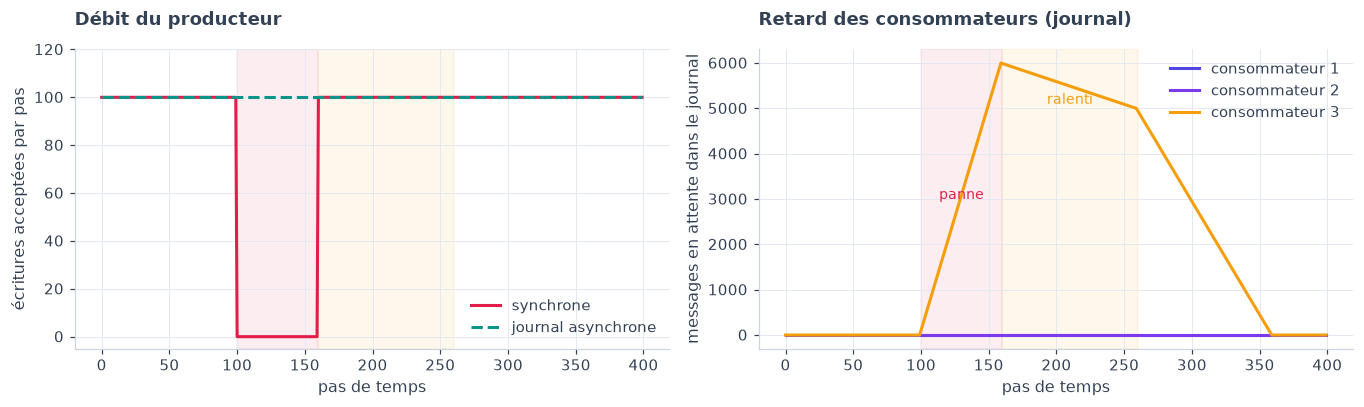

écritures perdues pour le producteur : synchrone 6000, journal 0 ; retard max du consommateur 3 : 6000 messages, résorbé au pas 359


In [6]:
T = 400
steps = np.arange(T)
cap3 = np.where((steps >= 100) & (steps < 160), 0, np.where((steps >= 160) & (steps < 260), 110, 150))
capacites = np.vstack([np.full(T, 150), np.full(T, 150), cap3])      # consommateurs x pas
sync = dfl.coupling_sim("sync", T, 100, capacites)
asyn = dfl.coupling_sim("async", T, 100, capacites)
acc_s, acc_a, bl_a = sync["accepted"], asyn["accepted"], asyn["backlog"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax1.plot(acc_s, color=ROSE, label="synchrone"); ax1.plot(acc_a, color=TEAL, label="journal asynchrone", ls="--")
ax1.axvspan(100, 160, color=ROSE, alpha=0.08); ax1.axvspan(160, 260, color=AMBER, alpha=0.08)
ax1.set_ylim(-5, 120); ax1.set_xlabel("pas de temps"); ax1.set_ylabel("écritures acceptées par pas")
ax1.set_title("Débit du producteur"); ax1.legend(loc="lower right")
for i, c in enumerate([INDIGO, VIOLET, AMBER]):
    ax2.plot(bl_a[i], color=c, label=f"consommateur {i + 1}")
ax2.axvspan(100, 160, color=ROSE, alpha=0.08); ax2.axvspan(160, 260, color=AMBER, alpha=0.08)
ax2.set_xlabel("pas de temps"); ax2.set_ylabel("messages en attente dans le journal")
ax2.set_title("Retard des consommateurs (journal)"); ax2.legend()
ax2.text(130, bl_a[2].max() * 0.5, "panne", ha="center", color=ROSE, fontsize=9)
ax2.text(210, bl_a[2].max() * 0.85, "ralenti", ha="center", color=AMBER, fontsize=9)
plt.tight_layout(); plt.show()
print(f"écritures perdues pour le producteur : synchrone {100 * 400 - acc_s.sum():.0f}, journal {100 * 400 - acc_a.sum():.0f} ; "
      f"retard max du consommateur 3 : {bl_a[2].max():.0f} messages, résorbé au pas {np.argmax((np.arange(400) > 160) & (bl_a[2] == 0))}")

En mode synchrone, la panne du consommateur 3 **arrête le producteur** pendant 60 pas
(6 000 écritures refusées) ; son ralentissement à 110 ne le gêne pas, puisque 110 reste
au-dessus du débit de 100 (un ralentissement sous 100 l'aurait bridé d'autant). Avec le
journal, le producteur ne voit rien, les consommateurs 1 et 2 non plus ; le consommateur
3 accumule 6 000 messages pendant sa panne, en rattrape lentement (10 par pas) pendant
son ralentissement, puis à pleine vitesse (50 par pas) : son retard est résorbé vers le
pas 360, sans rien perdre.

> **À retenir.** Un journal avec des consommateurs idempotents est l'interface de
> composition la plus robuste entre systèmes hétérogènes : il **contient** les pannes
> (un consommateur fautif prend du retard, personne d'autre n'en souffre) et permet à
> chaque équipe d'avancer indépendamment.

## 5. Dégroupé ou intégré ? (section *Unbundled versus integrated systems*)

Le dégroupage ne remplacera pas les bases de données : il en faut toujours pour tenir
l'état des processeurs de flux et servir les résultats des traitements, et les moteurs
spécialisés (les entrepôts pour l'analytique exploratoire) restent irremplaçables sur
leur terrain. Il a aussi un coût : chaque logiciel a sa courbe d'apprentissage, sa
configuration, ses bizarreries opérationnelles. Un produit intégré peut aussi être plus
performant et plus prévisible sur la charge pour laquelle il est conçu. D'où la
recommandation du livre : **déployer le moins de pièces mobiles possible**, et
construire pour une échelle dont on n'a pas besoin est une optimisation prématurée.

Ordre de grandeur : si chaque composant a, une semaine donnée, une probabilité $q$
d'incident opérationnel (montée de version qui casse, disque plein, configuration
erronée), la probabilité qu'**au moins un** composant d'un système à $n$ pièces soit en
incident vaut $1 - (1 - q)^n$.

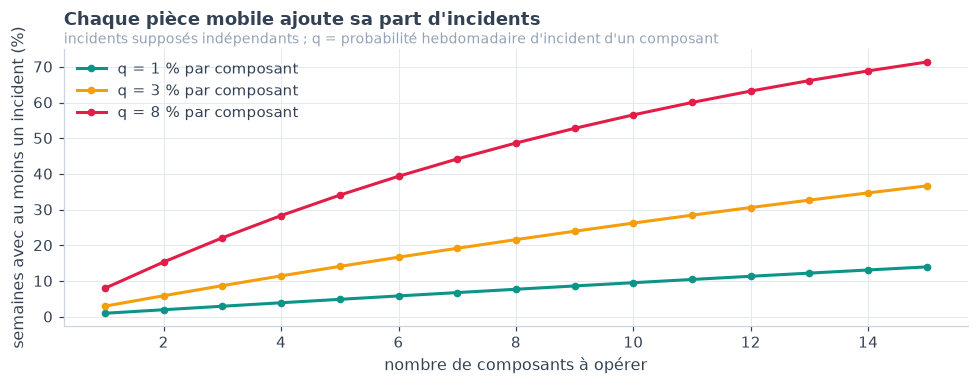

In [7]:
n = np.arange(1, 16)
fig, ax = plt.subplots(figsize=(9, 3.6))
for q, c in [(0.01, TEAL), (0.03, AMBER), (0.08, ROSE)]:
    ax.plot(n, (1 - (1 - q) ** n) * 100, "o-", ms=4, color=c, label=f"q = {q:.0%} par composant".replace("%", " %"))
ax.set_xlabel("nombre de composants à opérer"); ax.set_ylabel("semaines avec au moins un incident (%)")
ax.set_title("Chaque pièce mobile ajoute sa part d'incidents")
subtitle(ax, "incidents supposés indépendants ; q = probabilité hebdomadaire d'incident d'un composant")
ax.legend(); plt.tight_layout(); plt.show()

Avec dix composants à 3 % d'incidents hebdomadaires, plus d'une semaine sur quatre
(26 %) connaît au moins un incident. Le but du dégroupage n'est donc **pas** de battre une
base spécialisée sur sa charge de prédilection, mais de combiner plusieurs bases pour
couvrir **une gamme de charges plus large** qu'un seul logiciel : la **largeur**, pas la
profondeur. Si un seul produit fait tout ce dont vous avez besoin, utilisez-le ; le
dégroupage ne sert que quand aucun logiciel ne suffit seul.

Les outils de composition s'améliorent : Debezium extrait des flux de changements de
nombreuses bases, le protocole de Kafka devient un standard de fait pour les flux
d'événements, et les moteurs de **maintenance incrémentale de vues** (chapitre
12) précalculent et tiennent à jour des caches de requêtes complexes.

> **À retenir.** Dégrouper coûte des pièces mobiles. On ne dégroupe que pour la
> **largeur** (couvrir des charges qu'aucun produit ne couvre seul), jamais pour battre un
> produit intégré sur sa propre charge.

## 6. Le code applicatif comme fonction de dérivation : le modèle du tableur (sections *Designing Applications Around Dataflow* et *Application code as a derivation function*)

Mettre à jour automatiquement ce qui dépend d'une donnée quand elle change n'a rien de
neuf : c'est ce que fait un **tableur** depuis VisiCalc (1979). On écrit une formule dans
une cellule, et dès qu'une entrée change, le résultat est recalculé. C'est exactement ce
que l'on veut à l'échelle d'un système de données : qu'un changement d'enregistrement
mette à jour tous les index, caches et agrégats qui en dépendent, sans avoir à s'en
soucier. La différence : un système de données doit être tolérant aux pannes, passer à
l'échelle, stocker durablement, et intégrer des technologies écrites par des équipes
différentes.

Chaque donnée dérivée est produite par une **fonction de dérivation** :

| donnée dérivée | fonction de dérivation | fournie par la base ? |
|---|---|---|
| index secondaire | extraire les valeurs indexées, trier | oui (`CREATE INDEX`) |
| index plein texte | détection de langue, segmentation, racinisation, synonymes, puis index inversé | en partie (langues courantes) |
| modèle d'apprentissage | extraction de caractéristiques, statistiques sur les données d'entraînement | non (très spécifique à l'application) |
| cache pour l'interface | agréger les champs affichés par l'écran | non (dépend de l'interface) |

Dès que la fonction n'est pas standard, il faut du **code applicatif**, et c'est là que
les bases peinent : déclencheurs, procédures stockées et fonctions utilisateur existent,
mais ont toujours été un peu des pièces rapportées. Construisons un petit moteur de
dataflow façon tableur (`dfl.Dataflow`) : modifier une entrée ne recalcule que les
cellules qui en dépendent, dans l'ordre topologique.

In [8]:
g = dfl.Dataflow()
g.set("prix_ht", 100.0); g.set("tva", 0.20); g.set("quantite", 3); g.set("stock", 40)
g.define("prix_ttc", lambda p, t: round(p * (1 + t), 2), "prix_ht", "tva")
g.define("total", lambda p, q: p * q, "prix_ttc", "quantite")
g.define("stock_restant", lambda s, q: s - q, "stock", "quantite")
g.define("alerte_stock", lambda r: r < 10, "stock_restant")
g.define("facture", lambda tot, ttc: f"{tot:.2f} EUR ({ttc:.2f} l'unité)", "total", "prix_ttc")
n0 = g.recomputations
touched = g.set("tva", 0.055)
print("tva modifiée → recalcul de", touched, f"({g.recomputations - n0} cellules sur {len(g.formulas)})")
touched = g.set("quantite", 35)
print("quantite modifiée → recalcul de", touched, "; alerte :", g["alerte_stock"], ";", g["facture"])

tva modifiée → recalcul de ['prix_ttc', 'total', 'facture'] (3 cellules sur 5)
quantite modifiée → recalcul de ['total', 'stock_restant', 'alerte_stock', 'facture'] ; alerte : True ; 3692.50 EUR (105.50 l'unité)


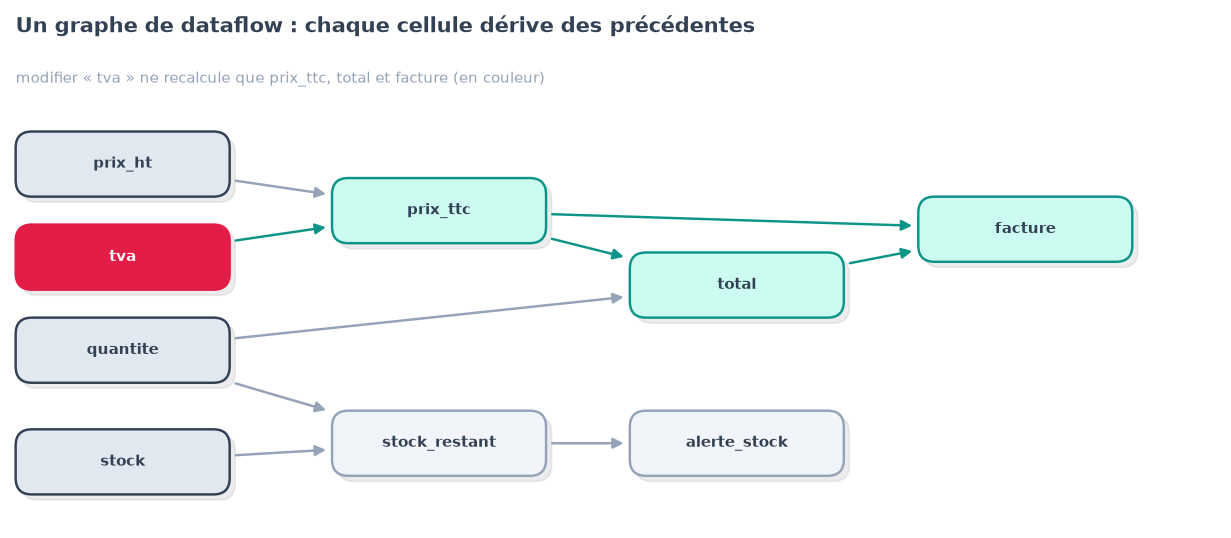

In [9]:
d = Diagram(13, 4.6, title="Un graphe de dataflow : chaque cellule dérive des précédentes",
            subtitle="modifier « tva » ne recalcule que prix_ttc, total et facture (en couleur)")
pos = {"prix_ht": (1.2, 3.9), "tva": (1.2, 2.9), "quantite": (1.2, 1.9), "stock": (1.2, 0.7),
       "prix_ttc": (4.6, 3.4), "total": (7.8, 2.6), "stock_restant": (4.6, 0.9),
       "facture": (10.9, 3.2), "alerte_stock": (7.8, 0.9)}
hot = {"tva", "prix_ttc", "total", "facture"}
for name, (x, y) in pos.items():
    is_input = name not in g.formulas
    d.box(name, x, y, name, color=(ROSE if name == "tva" else TEAL) if name in hot else (SLATE if is_input else GRAY),
          w=2.3, h=0.7, fontsize=9.5, filled=name == "tva")
for name, (fn, inputs) in g.formulas.items():
    for i in inputs:
        d.arrow(i, name, color=TEAL if (i in hot and name in hot) else GRAY)
d.show()

Sur un grand graphe, le gain de la propagation **incrémentale** par rapport au recalcul
complet est considérable. Mesurons-le sur des graphes aléatoires en couches (chaque
cellule dépend de deux cellules de la couche précédente).

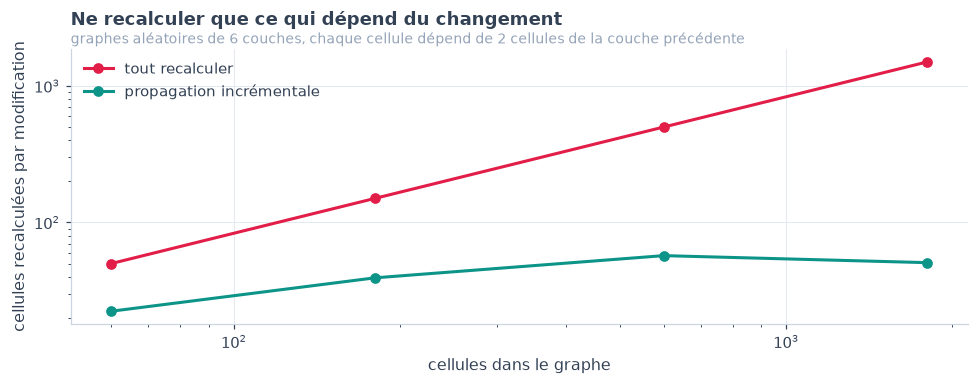

,cellules,recalculs par modification (incrémental),recalculs par modification (tout recalculer)
0,60,22.36,50
1,180,39.26,150
2,600,57.10,500
3,1800,50.72,1500


In [10]:
def layered_graph(n_layers, width, seed):
    rng = random.Random(seed)
    gg = dfl.Dataflow()
    for j in range(width):
        gg.set(f"c0_{j}", rng.random())
    for layer in range(1, n_layers):
        for j in range(width):
            a, b = rng.sample(range(width), 2)
            gg.define(f"c{layer}_{j}", lambda x, y: x + y, f"c{layer - 1}_{a}", f"c{layer - 1}_{b}")
    return gg

rows = []
for width in [10, 30, 100, 300]:
    gg = layered_graph(6, width, seed=width)
    n0 = gg.recomputations
    rng = random.Random(1)
    for _ in range(50):
        gg.set(f"c0_{rng.randrange(width)}", rng.random())
    rows.append({"cellules": 6 * width, "recalculs par modification (incrémental)": (gg.recomputations - n0) / 50,
                 "recalculs par modification (tout recalculer)": len(gg.formulas)})
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(R["cellules"], R.iloc[:, 2], "o-", color=ROSE, label="tout recalculer")
ax.plot(R["cellules"], R.iloc[:, 1], "o-", color=TEAL, label="propagation incrémentale")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("cellules dans le graphe"); ax.set_ylabel("cellules recalculées par modification")
ax.set_title("Ne recalculer que ce qui dépend du changement")
subtitle(ax, "graphes aléatoires de 6 couches, chaque cellule dépend de 2 cellules de la couche précédente")
ax.legend(); plt.tight_layout(); plt.show()
R

Avec 1 800 cellules, une modification n'en recalcule qu'une cinquantaine en moyenne (la
zone d'influence plafonne : elle dépend surtout du nombre de couches, pas de la largeur), contre 1 500 en
recalcul complet. C'est la promesse de la **maintenance incrémentale** : des vues
toujours à jour pour un coût proportionnel au **changement**, pas à la taille des
données.

> **À retenir.** Une donnée dérivée est le résultat d'une fonction de dérivation ; quand
> cette fonction est spécifique à l'application, elle sort naturellement de la base. Le
> modèle à viser est celui du tableur : déclarer les dépendances, et laisser le système
> propager les changements, incrémentalement.

## 7. Séparer le code et l'état, et s'abonner aux changements (sections *Separation of application code and state* et *Dataflow: Interplay between state changes and application code*)

En théorie, une base pourrait héberger du code arbitraire, comme un système
d'exploitation. En pratique elle s'y prête mal : gestion des dépendances et des
paquets, contrôle de version, déploiements progressifs, supervision, appels réseau...
Des outils dédiés au déploiement et à la gestion de clusters (Kubernetes, Docker, Mesos, YARN) font ce travail beaucoup
mieux. La tendance est donc de séparer la **logique sans état** (les serveurs
d'application, que l'on ajoute et retire à volonté) de la **gestion de l'état** (la base).
Les programmeurs fonctionnels en plaisantent : ils croient à la séparation de *Church*
et de l'État (Alonzo Church a inventé le lambda-calcul, qui n'a pas d'état mutable).

Dans ce modèle, la base est une **variable partagée mutable**, accessible par le réseau.
Mais dans la plupart des langages, on ne peut pas **s'abonner** aux changements d'une
variable, seulement la relire (le motif observateur existe, mais n'est pas intégré) ; et
les bases ont hérité de cette passivité : pour savoir si quelque chose a changé, on
**interroge en boucle** (polling). Penser en flux de données, c'est renverser la
relation : le code **réagit** aux changements d'état d'un endroit en provoquant des
changements ailleurs (CDC, acteurs, déclencheurs, maintenance de vues).

Démonstration avec SQLite : des déclencheurs publient chaque changement de la table
`products` dans une table `changelog` (`dfl.make_changelog_db`). Un consommateur lit ce
journal **par offset** et tient à jour une vue dérivée (nombre de produits par tranche de
prix), sans jamais relire la table.

In [11]:
db = dfl.make_changelog_db()
rng = random.Random(8)
for i in range(1, 201):
    db.execute("INSERT INTO products VALUES (?, ?, ?)", (i, f"produit {i}", round(rng.uniform(1, 100), 2)))
for _ in range(300):
    i = rng.randrange(1, 201)
    if rng.random() < 0.1:
        db.execute("DELETE FROM products WHERE id = ?", (i,))
    else:
        db.execute("UPDATE products SET price = ? WHERE id = ?", (round(rng.uniform(1, 100), 2), i))

def tranche(prix):
    return f"{int(prix // 25) * 25}-{int(prix // 25) * 25 + 25} EUR"

class VueParTranche:
    """Consommateur du journal de changements : vue dérivée, entretenue par offset."""
    def __init__(self):
        self.offset, self.prix, self.compte = 0, {}, {}
    def consommer(self, conn, perdre=None):
        for seq, op, pid, _, price in conn.execute("SELECT seq, op, id, name, price FROM changelog WHERE seq > ? "
                                                   "ORDER BY seq", (self.offset,)):
            self.offset = seq
            if perdre is not None and seq == perdre:
                continue                                   # message perdu : la vue dérive pour toujours
            if pid in self.prix:
                old = tranche(self.prix.pop(pid)); self.compte[old] -= 1
            if op == "put":
                self.prix[pid] = price; t = tranche(price); self.compte[t] = self.compte.get(t, 0) + 1

perdu = db.execute("SELECT MIN(seq) FROM changelog WHERE op = 'del'").fetchone()[0]   # une suppression perdue
v_ok, v_perte = VueParTranche(), VueParTranche()
v_ok.consommer(db); v_perte.consommer(db, perdre=perdu)
verite = dict(db.execute("SELECT CAST(price / 25 AS INT) * 25, COUNT(*) FROM products GROUP BY 1"))
cmp = pd.DataFrame({"recalcul depuis la table": {f"{k}-{k + 25} EUR": c for k, c in verite.items()},
                    "vue dérivée (journal complet)": v_ok.compte,
                    "vue dérivée (1 message perdu)": v_perte.compte}).fillna(0).astype(int)
print("entrées du journal lues :", v_ok.offset)
cmp

entrées du journal lues : 478


,recalcul depuis la table,vue dérivée (journal complet),vue dérivée (1 message perdu)
0-25 EUR,54,54,55
25-50 EUR,49,49,49
50-75 EUR,39,39,39
75-100 EUR,36,36,36


La vue entretenue par le journal coïncide avec le recalcul complet. Mais il suffit de
**perdre un seul message** (ici une suppression) pour qu'elle dérive définitivement :
un produit disparu reste compté dans sa tranche, à jamais. D'où les deux exigences du livre pour entretenir des données
dérivées, que les courtiers à base de journal satisfont :

- l'**ordre** des changements compte (plusieurs vues dérivées du même journal doivent les
  traiter dans le même ordre pour rester cohérentes entre elles) ;
- la **tolérance aux pannes** est indispensable : livraison des messages **et** mise à
  jour de l'état dérivé doivent être fiables.

Ces exigences sont fortes, mais bien moins coûteuses et plus robustes que des
transactions distribuées ; les moteurs de flux modernes les offrent à grande échelle et
permettent d'exécuter du code applicatif arbitraire comme opérateur, composable comme
des outils Unix reliés par des tubes.

> **À retenir.** Séparer le code sans état de l'état persistant a fait de la base une
> variable passive qu'on interroge en boucle. Le dataflow renverse la relation : on
> s'**abonne** aux changements, et le code les transforme en d'autres changements. Il
> exige ordre et fiabilité : un message perdu, et la vue est fausse pour toujours.

## 8. Processeurs de flux et services (section *Stream processors and services*)

Le style dominant découpe une application en **services** qui s'appellent par des
requêtes synchrones (REST, RPC). L'avantage principal est organisationnel : des équipes
différentes travaillent sur des services différents, déployés indépendamment. Composer
des opérateurs de flux a les mêmes qualités, mais un mécanisme de communication très
différent : des **flux de messages asynchrones et unidirectionnels** au lieu de
requêtes-réponses.

L'exemple du livre : un client achète un article affiché dans une devise et paie dans
une autre. Il faut le **taux de change courant**. Deux façons de faire :

- **microservices** : le code qui traite l'achat interroge un service de taux de change ;
- **dataflow** : le code qui traite l'achat s'est **abonné à l'avance** au flux des mises à
  jour du taux et le garde dans une base **locale** ; il n'a qu'à la lire.

Simulons 200 000 achats : l'appel au service distant a une latence log-normale (médiane
2 ms, queue lourde) et le service tombe en panne 10 minutes sur une journée ; la lecture
locale coûte 20 microsecondes.

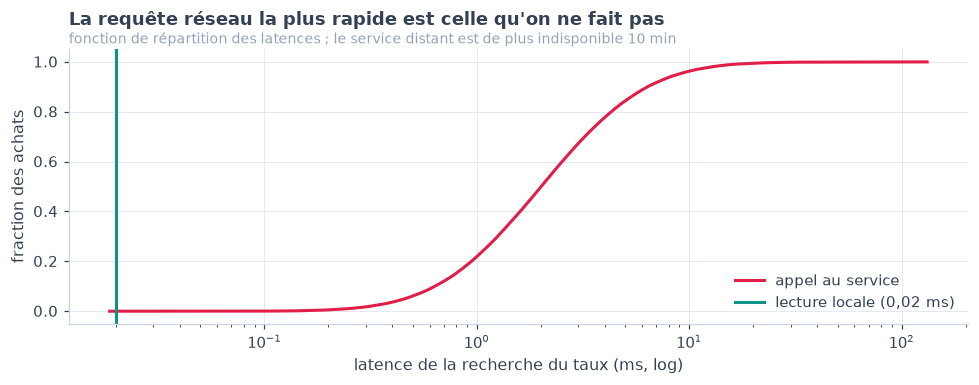

,approche,médiane (ms),p99 (ms),"p99,9 (ms)",achats échoués (panne du service)
0,appel au service (RPC),2.011,16.049,32.883,1393
1,abonnement + table locale,0.020,0.020,0.020,0


In [12]:
rng = np.random.default_rng(2)
n_ach = 200_000
t_ach = np.sort(rng.uniform(0, 86_400, n_ach))
rpc = rng.lognormal(np.log(2.0), 0.9, n_ach)                 # ms
panne = (t_ach > 40_000) & (t_ach < 40_600)
local = np.full(n_ach, 0.02)
stats = pd.DataFrame({
    "approche": ["appel au service (RPC)", "abonnement + table locale"],
    "médiane (ms)": [np.median(rpc[~panne]), np.median(local)],
    "p99 (ms)": [np.quantile(rpc[~panne], 0.99), np.quantile(local, 0.99)],
    "p99,9 (ms)": [np.quantile(rpc[~panne], 0.999), np.quantile(local, 0.999)],
    "achats échoués (panne du service)": [int(panne.sum()), 0]})
fig, ax = plt.subplots(figsize=(9, 3.6))
xs = np.sort(rpc[~panne]); ax.plot(xs, np.arange(1, xs.size + 1) / xs.size, color=ROSE, label="appel au service")
ax.axvline(0.02, color=TEAL, lw=2, label="lecture locale (0,02 ms)")
ax.set_xscale("log"); ax.set_xlabel("latence de la recherche du taux (ms, log)"); ax.set_ylabel("fraction des achats")
ax.set_title("La requête réseau la plus rapide est celle qu'on ne fait pas")
subtitle(ax, "fonction de répartition des latences ; le service distant est de plus indisponible 10 min")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
stats

La lecture locale est cent fois plus rapide en médiane, plus de mille fois au p99,9, et
**insensible à la panne** du service de taux (environ 1 400 achats échouent sinon). On
pourrait mettre le taux en cache côté microservice, mais pour garder ce cache frais il
faudrait interroger périodiquement le service ou s'abonner à ses changements... ce qui
est précisément l'approche dataflow. Le RPC est remplacé par une **jointure flux-table**
entre les achats et les mises à jour de taux.

**Une jointure dépendante du temps.** Si l'on **retraite** plus tard les achats (pour
corriger un bogue, ou dériver une nouvelle vue), le taux aura changé. Pour reproduire le
résultat d'origine, il faut le taux **historique** en vigueur à l'instant de chaque achat :
une jointure « as of » (`dfl.asof_join`), comme les jointures de flux dépendantes du temps
du chapitre 12.

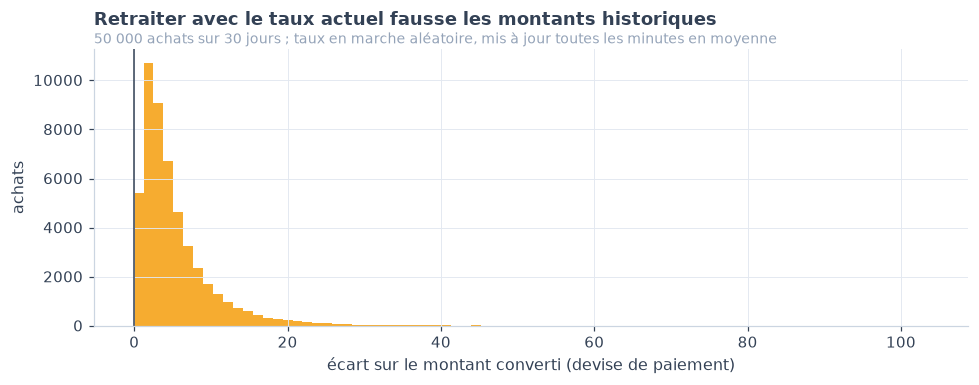

taux : de 1.088 à 1.165 sur la période ; écart absolu moyen 5.42  somme des écarts 270 806


In [13]:
rt, rv = dfl.random_walk_rates(seed=4, horizon=86_400 * 30, mean_interval=60, vol=0.0002)
t_buy = np.sort(np.random.default_rng(5).uniform(0, 86_400 * 30, 50_000))
amount = np.random.default_rng(6).lognormal(np.log(80), 0.8, t_buy.size)
taux_hist = dfl.asof_join(t_buy, rt, rv)
taux_actuel = rv[-1]
err = amount * (taux_actuel - taux_hist)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(err, bins=80, color=AMBER, alpha=0.85)
ax.axvline(0, color=SLATE, lw=1)
ax.set_xlabel("écart sur le montant converti (devise de paiement)"); ax.set_ylabel("achats")
ax.set_title("Retraiter avec le taux actuel fausse les montants historiques")
subtitle(ax, "50 000 achats sur 30 jours ; taux en marche aléatoire, mis à jour toutes les minutes en moyenne")
plt.tight_layout(); plt.show()
print(f"taux : de {rv.min():.3f} à {rv.max():.3f} sur la période ; écart absolu moyen {np.abs(err).mean():.2f}, "
      f"somme des écarts {err.sum():,.0f}".replace(",", " "))

Rejoindre avec le taux courant décale presque tous les montants, de plusieurs unités en
moyenne, et la somme des écarts est loin d'être nulle : le retraitement ne reproduit pas
le passé. Qu'on interroge un service ou qu'on s'abonne à un flux, il faut gérer cette
**dépendance au temps** (versionner les taux, ou journaliser le taux utilisé avec
l'achat).

> **À retenir.** S'abonner à un flux de changements et garder une copie locale remplace
> un appel réseau synchrone par une lecture locale : plus rapide, et insensible aux
> pannes de l'autre service. On se rapproche du modèle du tableur. La jointure devient
> dépendante du temps : pour retraiter fidèlement, il faut l'état **historique**.

## Synthèse

- Bases de données et Unix incarnent deux philosophies ; **dégrouper la base**, c'est
  fournir ses fonctions (index, vues, déclencheurs) par des systèmes spécialisés reliés
  par un journal, qui joue le rôle du WAL de l'organisation.
- `CREATE INDEX` (instantané + rattrapage + suivi) est la même mécanique que l'ajout d'un
  suiveur (chapitre 6) ou l'amorçage d'un CDC (chapitre 12) : un
  index est une vue dérivée.
- La **fédération** unifie les lectures, le **dégroupage** unifie les écritures ; son atout
  est le **couplage lâche**, technique (pannes contenues) et humain (équipes
  indépendantes). Son coût : des pièces mobiles. On dégroupe pour la largeur, pas pour la
  profondeur.
- Le modèle visé est celui du **tableur** : du code applicatif comme fonction de
  dérivation, des abonnements aux changements plutôt que du polling, une propagation
  incrémentale. Il exige ordre et fiabilité de bout en bout.
- Entre services, s'abonner à un flux et joindre localement remplace des appels
  synchrones (plus rapide, plus robuste), au prix de jointures dépendantes du temps.

Le cours 3 regarde l'autre extrémité du flux : comment l'état dérivé est **lu**, jusqu'à
l'écran de l'utilisateur.